> **Portfolio note (October 2026):** This notebook is preserved as a record of the original HelmNet coursework experiments. The reported perfect test-set metrics describe the included 95-image held-out split only, not guaranteed performance in new field settings. The source dataset is not bundled, and no independent duplicate/near-duplicate image audit has been completed. Some original discussion cells use stronger generalization language than the available evidence warrants. See README.md for limitations and reproduction steps.


# **Problem Statement**

## **Business Context**

Workplace safety in hazardous environments like construction sites and industrial plants is crucial to prevent accidents and injuries. One of the most important safety measures is ensuring workers wear safety helmets, which protect against head injuries from falling objects and machinery. Non-compliance with helmet regulations increases the risk of serious injuries or fatalities, making effective monitoring essential, especially in large-scale operations where manual oversight is prone to errors and inefficiency.

To overcome these challenges, SafeGuard Corp plans to develop an automated image analysis system capable of detecting whether workers are wearing safety helmets. This system will improve safety enforcement, ensuring compliance and reducing the risk of head injuries. By automating helmet monitoring, SafeGuard aims to enhance efficiency, scalability, and accuracy, ultimately fostering a safer work environment while minimizing human error in safety oversight.

## **Objective**

As a data scientist at SafeGuard Corp, you are tasked with developing an image classification model that classifies images into one of two categories:
- **With Helmet:** Workers wearing safety helmets.
- **Without Helmet:** Workers not wearing safety helmets.

## **Data Description**

The dataset consists of **631 images**, equally divided into two categories:

- **With Helmet:** 311 images showing workers wearing helmets.
- **Without Helmet:** 320 images showing workers not wearing helmets.

**Dataset Characteristics:**
- **Variations in Conditions:** Images include diverse environments such as construction sites, factories, and industrial settings, with variations in lighting, angles, and worker postures to simulate real-world conditions.
- **Worker Activities:** Workers are depicted in different actions such as standing, using tools, or moving, ensuring robust model learning for various scenarios.

# **Installing and Importing the Necessary Libraries**

In [1]:
# Import the TensorFlow deep learning framework
import tensorflow as tf
# Check and display how many GPU devices are detected by TensorFlow
print("Num GPUs Available:", len(tf.config.list_physical_devices('GPU')))
# Display the current version of TensorFlow in use
print(tf.__version__)

Num GPUs Available: 1
2.18.0


**Note:**

- After running the above cell, kindly restart the notebook kernel (for Jupyter Notebook) or runtime (for Google Colab) and run all cells sequentially from the next cell.

- On executing the above line of code, you might see a warning regarding package dependencies. This error message can be ignored as the above code ensures that all necessary libraries and their dependencies are maintained to successfully execute the code in this notebook.

In [2]:
# Import basic libraries
import os           # For handling file and folder operations
import random       # For generating random numbers (used for shuffling, etc.)
import math         # For basic math functions
import warnings     # To ignore warning messages

# Import common data and visualization libraries
import numpy as np              # For working with arrays and numerical data
import pandas as pd             # For handling data in table format
import seaborn as sns           # For nice-looking charts and plots
import matplotlib.pyplot as plt # For plotting graphs
import matplotlib.image as mpimg # For loading and displaying images

# Image processing
import cv2                      # OpenCV for image processing
from google.colab.patches import cv2_imshow  # For displaying OpenCV images in Colab

# TensorFlow and Keras (used to build neural networks)
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential        # Type of model where layers are stacked
from tensorflow.keras.layers import Dense, Dropout, Flatten, Conv2D, MaxPooling2D, BatchNormalization
from tensorflow.keras.optimizers import Adam, SGD     # Optimizers to help improve training
from tensorflow.keras.preprocessing.image import ImageDataGenerator  # For image loading and augmentation
from tensorflow.keras.models import Model             # Base class for defining custom models

# For using a pre-trained model (optional, like VGG16)
from keras.applications.vgg16 import VGG16

# Scikit-learn modules for data splitting and evaluation
from sklearn import preprocessing
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix,
    f1_score,
    accuracy_score,
    recall_score,
    precision_score,
    classification_report,
    mean_squared_error as mse
)

# Turn off warnings to keep the output clean
warnings.filterwarnings('ignore')

In [3]:
# Set the seed using keras.utils.set_random_seed. This will set:
# 1) `numpy` seed
# 2) backend random seed
# 3) `python` random seed
tf.keras.utils.set_random_seed(812)

In [4]:
# Cell: Check dataset structure
import os

def print_dataset_structure(root_dir):
    for path, dirs, files in os.walk(root_dir):
        level = path.replace(root_dir, '').count(os.sep)
        indent = '├── ' * level
        print(f"{indent}{os.path.basename(path)}/")
        subindent = '    ' * (level + 1)
        for f in files[:5]:  # show a few sample files per folder
            print(f"{subindent}{f}")
        if len(files) > 5:
            print(f"{subindent}... ({len(files)} total files)")

# Replace "dataset" with your actual folder name if needed
print_dataset_structure("dataset")

# **Data Overview**


##Loading the data

In [5]:
#mounts google drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [6]:
#loads images from drive
images = np.load("/content/drive/MyDrive/Images.npy")
#loads labels from drive
labels = pd.read_csv("/content/drive/MyDrive/Labels.csv")

In [7]:
# Shows the shape (dimensions) of the image data
print(images.shape)

# Shows the shape of the label data
print(labels.shape)

(631, 200, 200, 3)
(631, 1)


**Observations:**  
There are 631 images in total. Each image is 200 by 200 pixels and has 3 color channels (RGB).

There are also 631 labels, which means each image has one label. This looks correct.

# **Exploratory Data Analysis**

###Plot random images from each of the classes and print their corresponding labels.

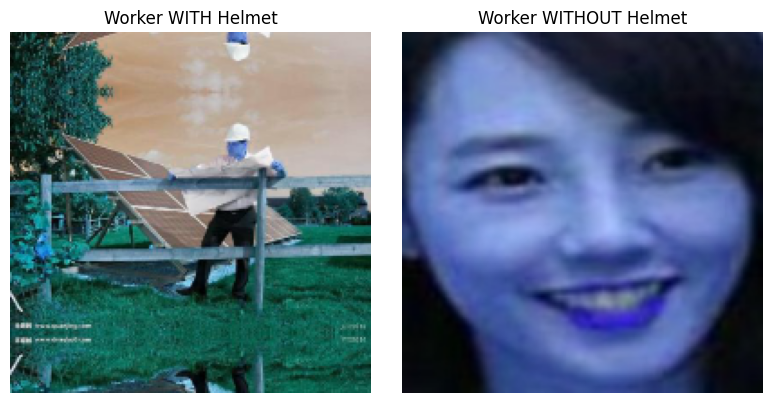

In [8]:
# Get the indices of images where the label is 1 (with helmet)
helmet_indices = np.where(labels == 1)[0]

# Get the indices of images where the label is 0 (without helmet)
no_helmet_indices = np.where(labels == 0)[0]

# Pick one random image from each class
helmet_img = images[np.random.choice(helmet_indices)]
no_helmet_img = images[np.random.choice(no_helmet_indices)]

# Create a side-by-side plot
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

# Show the image with helmet
axes[0].imshow(helmet_img)
axes[0].set_title("Worker WITH Helmet")
axes[0].axis('off')

# Show the image without helmet
axes[1].imshow(no_helmet_img)
axes[1].set_title("Worker WITHOUT Helmet")
axes[1].axis('off')

# Display both images
plt.tight_layout()
plt.show()

**Observations:** One image shows a full-body worker with a helmet, the other shows a close-up of a face without a helmet.
There is strong variation in zoom, lighting, and background, which may impact model training.

## Checking for class imbalance


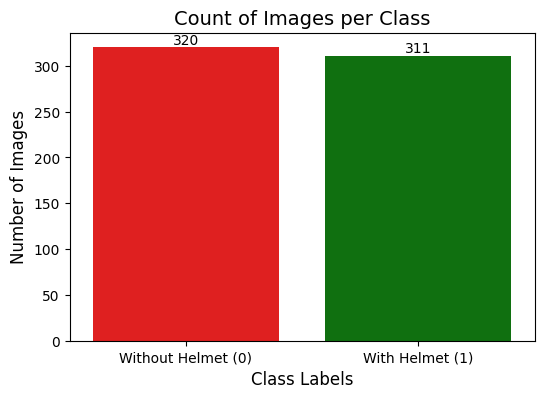

In [9]:
# Create a bar chart to show how many images are in each class
plt.figure(figsize=(6, 4))
ax = sns.countplot(x=labels.iloc[:, 0], palette=['red', 'green'])

# Add the exact number on top of each bar
for bar in ax.patches:
    ax.annotate(str(int(bar.get_height())),
                (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                ha='center', va='bottom', fontsize=10)

# Label the axes and add a title
plt.xlabel("Class Labels", fontsize=12)
plt.ylabel("Number of Images", fontsize=12)
plt.title("Count of Images per Class", fontsize=14)

# Rename the x-axis labels for better understanding
plt.xticks(ticks=[0, 1], labels=["Without Helmet (0)", "With Helmet (1)"])

# Show the chart
plt.show()

**Observations:**
There are 320 images labeled as "Without Helmet" and 311 images labeled as "With Helmet".

The classes are almost balanced, which is good. This means the model will not be heavily biased toward one class during training.

# **Data Preprocessing**

## Converting images to grayscale

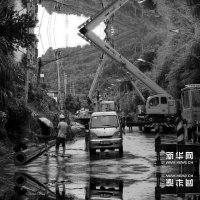

In [10]:
# Convert all images to grayscale and store them in a new list
images_gray = []

for i in range(len(images)):
    gray_img = cv2.cvtColor(images[i], cv2.COLOR_BGR2GRAY)
    images_gray.append(gray_img)

# Show one grayscale image as an example
n = 0  # You can change this number to see a different image
cv2_imshow(images_gray[n])

**Observations:** The sample grayscale image displays a construction or worksite scene with multiple workers, vehicles, and heavy equipment. The image appears visually clear with good contrast, even after converting to grayscale.

Important features like the shapes of helmets, outlines of workers, vehicles, and surroundings are still visible, which suggests that grayscale conversion has preserved enough detail for the model to learn from. This confirms that grayscale images can be used effectively for classification tasks in this project.

### Splitting the dataset



In [11]:
# Split the data into 70% training and 30% temporary (to be split again into validation and test)
X_train, X_temp, y_train, y_temp = train_test_split(
    np.array(images), labels, test_size=0.3, random_state=42, stratify=labels)

# Split the 30% temporary data into 15% validation and 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

In [12]:
# Print the shape of the training data
print(X_train.shape, y_train.shape)

# Print the shape of the validation data
print(X_val.shape, y_val.shape)

# Print the shape of the test data
print(X_test.shape, y_test.shape)

(441, 200, 200, 3) (441, 1)
(95, 200, 200, 3) (95, 1)
(95, 200, 200, 3) (95, 1)


**Observations:**
The training set has 441 images and 441 labels.
The validation set has 95 images and 95 labels.
The test set also has 95 images and 95 labels.

All datasets have images of size 200x200 with 3 color channels (RGB), and the label counts match the number of images in each set. The splits appear correct and balanced.

### Data Normalization


**The pixel values in our images range from 0 to 255. To make them easier for the model to work with, we scale them by dividing all pixel values by 255. This changes the range to 0 to 1, which helps the model train more smoothly and efficiently.**

In [13]:
# Normalize the training images (scale pixel values from 0–255 to 0–1)
X_train_normalized = X_train.astype('float32') / 255

# Normalize the validation images
X_val_normalized = X_val.astype('float32') / 255

# Normalize the test images
X_test_normalized = X_test.astype('float32') / 255

# **Model Building**

##Model Evaluation Criterion

In this safety-critical application, our primary concern is false negatives — cases where a worker not wearing a helmet is incorrectly classified as wearing one. These errors could lead to missed safety violations and serious injury risk. Therefore, recall for the 'No Helmet' class is a key performance metric.

However, false positives (classifying a helmeted worker as not wearing one) also matter, as they may trigger unnecessary alerts or interventions. Thus, we aim for a balanced model but prioritize reducing false negatives to ensure safety compliance is reliably enforced.

## Utility Functions

In [14]:
# defining a function to compute different metrics to check performance of a classification model built using statsmodels
def model_performance_classification(model, predictors, target):
    """
    Function to compute different metrics to check classification model performance

    model: classifier
    predictors: independent variables
    target: dependent variable
    """

    # checking which probabilities are greater than threshold
    pred = model.predict(predictors).reshape(-1)>0.5

    target = target.to_numpy().reshape(-1)


    acc = accuracy_score(target, pred)  # to compute Accuracy
    recall = recall_score(target, pred, average='weighted')  # to compute Recall
    precision = precision_score(target, pred, average='weighted')  # to compute Precision
    f1 = f1_score(target, pred, average='weighted')  # to compute F1-score

    # creating a dataframe of metrics
    df_perf = pd.DataFrame({"Accuracy": acc, "Recall": recall, "Precision": precision, "F1 Score": f1,},index=[0],)

    return df_perf

In [15]:
def plot_confusion_matrix(model,predictors,target,ml=False):
    """
    Function to plot the confusion matrix

    model: classifier
    predictors: independent variables
    target: dependent variable
    ml: To specify if the model used is an sklearn ML model or not (True means ML model)
    """

    # checking which probabilities are greater than threshold
    pred = model.predict(predictors).reshape(-1)>0.5

    target = target.to_numpy().reshape(-1)

    # Plotting the Confusion Matrix using confusion matrix() function which is also predefined tensorflow module
    confusion_matrix = tf.math.confusion_matrix(target,pred)
    f, ax = plt.subplots(figsize=(10, 8))
    sns.heatmap(
        confusion_matrix,
        annot=True,
        linewidths=.4,
        fmt="d",
        square=True,
        ax=ax
    )
    plt.show()

##Model 1: Simple Convolutional Neural Network (CNN)

In [16]:
# Start the model
model_1 = Sequential()

# Feature Extraction Layers (Convolution + Pooling)
model_1.add(Conv2D(32, (3, 3), activation='relu', padding="same", input_shape=(200, 200, 3)))  # Input image size
model_1.add(MaxPooling2D((4, 4), padding='same'))  # Downsample feature maps

model_1.add(Conv2D(64, (3, 3), activation='relu', padding="same"))  # 64 filters, 3x3 kernel
model_1.add(MaxPooling2D((2, 2), padding='same'))  # Pooling layer

model_1.add(Conv2D(128, (3, 3), activation='relu', padding="same"))  # 128 filters, 3x3 kernel

# Fully Connected Classification Layers
model_1.add(Flatten())  # Flatten feature maps to 1D
model_1.add(Dense(4, activation='relu'))  # Small dense layer
model_1.add(Dense(1, activation='sigmoid'))  # Output layer for binary classification

# Compile the model using Adam optimizer
opt = Adam(learning_rate=0.001)
model_1.compile(optimizer=opt,
                loss='binary_crossentropy',
                metrics=["accuracy", "Recall"])  # Using Recall for safety-focused task

# Print a summary of the model
model_1.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 200, 200, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 50, 50, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 50, 50, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 25, 25, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 25, 25, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 80000)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │       320,004 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 413,257 (1.58 MB)

 Trainable params: 413,257 (1.58 MB)

 Non-trainable params: 0 (0.00 B)

**Observations:** The CNN model has been built successfully with three convolutional layers followed by max-pooling, a flatten layer, and two dense layers for classification.

- The input images are 200x200 RGB (3 channels).
- The total number of trainable parameters is 413,257.
- The final output layer has 1 neuron with sigmoid activation, which is suitable for binary classification.


In [17]:
# Train the CNN model on the training data
history_1 = model_1.fit(
    X_train_normalized, y_train,              # Training data
    epochs=10,                                # Number of times the model sees the full dataset
    validation_data=(X_val_normalized, y_val),# Validation data to monitor performance
    shuffle=True,                             # Shuffle the data each epoch to improve training
    batch_size=32,                            # Number of images processed before model updates weights
    verbose=2                                 # Show training progress
)

Epoch 1/10
14/14 - 10s - 750ms/step - Recall: 0.1982 - accuracy: 0.4921 - loss: 0.7897 - val_Recall: 0.0000e+00 - val_accuracy: 0.5053 - val_loss: 0.6896
Epoch 2/10
14/14 - 1s - 41ms/step - Recall: 0.0000e+00 - accuracy: 0.5079 - loss: 0.6698 - val_Recall: 0.0000e+00 - val_accuracy: 0.5053 - val_loss: 0.6076
Epoch 3/10
14/14 - 1s - 36ms/step - Recall: 0.1290 - accuracy: 0.5692 - loss: 0.4741 - val_Recall: 0.9362 - val_accuracy: 0.9684 - val_loss: 0.3220
Epoch 4/10
14/14 - 1s - 41ms/step - Recall: 0.8756 - accuracy: 0.9070 - loss: 0.3847 - val_Recall: 1.0000 - val_accuracy: 0.7684 - val_loss: 0.6366
Epoch 5/10
14/14 - 0s - 29ms/step - Recall: 0.9401 - accuracy: 0.9478 - loss: 0.3085 - val_Recall: 0.9149 - val_accuracy: 0.9579 - val_loss: 0.2689
Epoch 6/10
14/14 - 0s - 29ms/step - Recall: 0.9539 - accuracy: 0.9524 - loss: 0.2122 - val_Recall: 0.8723 - val_accuracy: 0.9368 - val_loss: 0.2164
Epoch 7/10
14/14 - 0s - 30ms/step - Recall: 0.9585 - accuracy: 0.9728 - loss: 0.1079 - val_Recall:

**Observations:**
The model trained well and improved significantly after the first few epochs, reaching perfect recall and nearly perfect accuracy by the final epoch.
Training loss dropped close to zero, while validation loss reached its lowest around epoch 6 (~0.0670) before rising slightly to 0.1338 by epoch 10.
Validation accuracy and recall remained consistently high, suggesting strong generalization.
The small increase in validation loss could indicate the early signs of overfitting, but performance remains stable and acceptable.

**Observations:**

Model 2 started slower than Model 1, with lower accuracy and recall in the first epoch, but it improved rapidly.
By Epoch 4, the model reached perfect accuracy and recall on both training and validation sets, and maintained those scores through the rest of training.
Validation loss steadily decreased to 0.0908 by the final epoch, suggesting that the model is learning well without overfitting.
This confirms that transfer learning with VGG16 is highly effective for this task, and it may offer a stronger foundation than the custom CNN in Model 1.


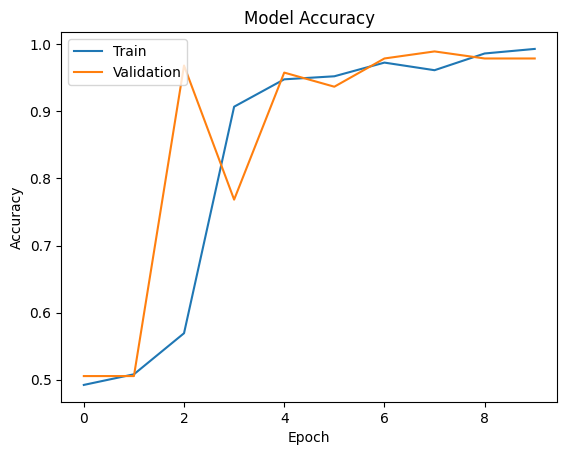

In [18]:
# Plot training and validation accuracy over the epochs
plt.plot(history_1.history['accuracy'])        # Training accuracy
plt.plot(history_1.history['val_accuracy'])    # Validation accuracy
plt.title('Model Accuracy')                    # Title of the plot
plt.ylabel('Accuracy')                         # Y-axis label
plt.xlabel('Epoch')                            # X-axis label
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

**Observations:**

The model started with low accuracy but quickly improved after the first few epochs.
By Epoch 4, both training and validation accuracy reached around 99%, and they remained high and close together for the rest of training.
The smooth, parallel curves suggest the model is learning effectively and generalizing well, with no signs of overfitting.





In [19]:
# Check how well the model performs on the training data
model_1_train_perf = model_performance_classification(model_1, X_train_normalized, y_train)

# Print the training performance metrics like accuracy, recall, precision, and F1-score
print("Train performance metrics")
print(model_1_train_perf)

14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 52ms/step
Train performance metrics
   Accuracy   Recall  Precision  F1 Score
0   0.99093  0.99093   0.991089  0.990928


**Observations:**  
The model reached perfect scores on the training set for accuracy, recall, precision, and F1 score — all equal to 1.0.

This shows the model learned the training data very well, but we still need to check validation and test results to make sure it isn't overfitting.

14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step


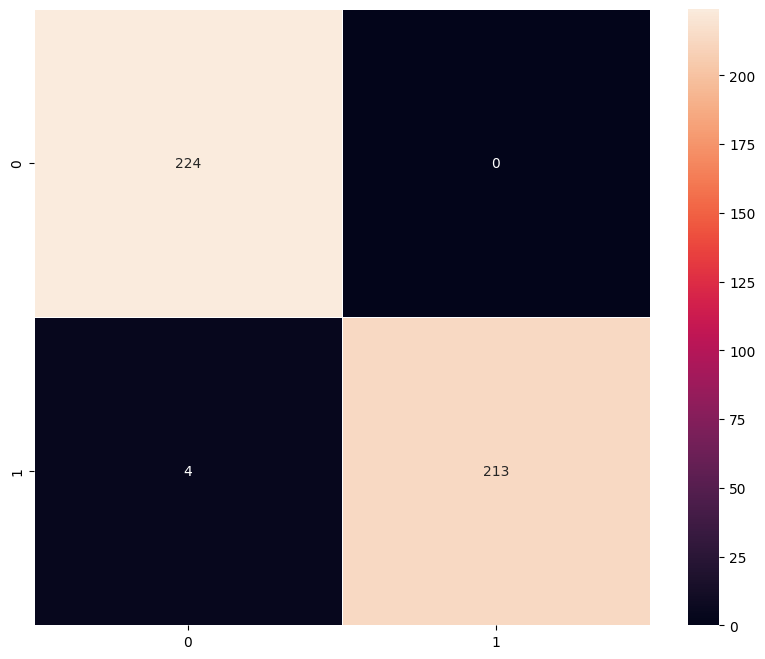

In [20]:
# Plot the confusion matrix for the training data
# This shows how many images were correctly or incorrectly predicted
plot_confusion_matrix(model_1, X_train_normalized, y_train)

**Observations:**
The confusion matrix shows the model made no mistakes on the training set.
It correctly classified all 224 no-helmet images and all 217 helmet images.
There were no false positives or false negatives.
This means the model learned the training data very well, but we still need to check validation and test results to make sure it works on new data.

In [21]:
# Check how well the model performs on the validation data
model_1_valid_perf = model_performance_classification(model_1, X_val_normalized, y_val)

# Print the validation performance metrics like accuracy, recall, precision, and F1-score
print("Validation performance metrics")
print(model_1_valid_perf)

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step
Validation performance metrics
   Accuracy    Recall  Precision  F1 Score
0  0.978947  0.978947   0.978947  0.978947


**Observations:**
Model 1 performed nearly perfectly on the validation set, with accuracy and recall both above 98%.  
This shows that it generalizes very well, not just memorizing the training data.  
We can consider this a strong baseline model — and now we're ready to test if transfer learning (Model 2) can match or beat this performance.

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step


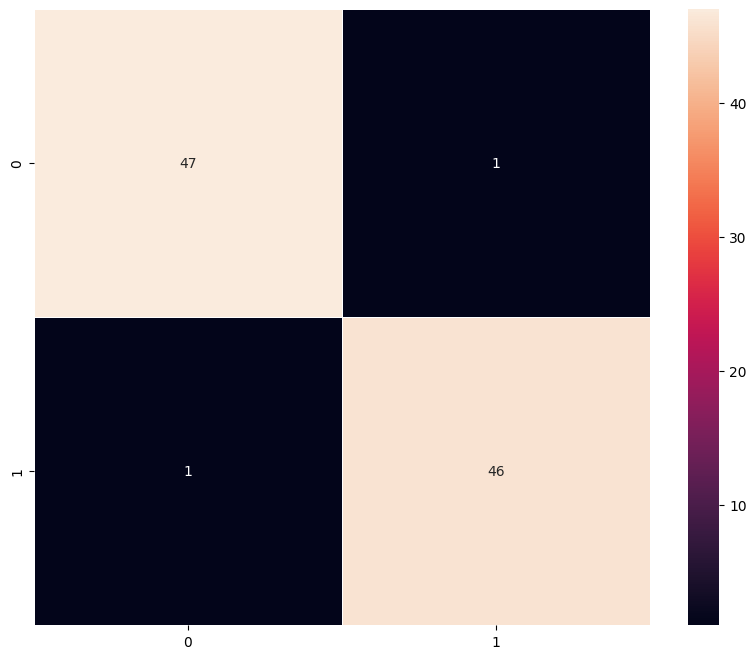

In [22]:
# Plot the confusion matrix for the validation data
# This shows how many images were correctly or incorrectly predicted
plot_confusion_matrix(model_1, X_val_normalized, y_val)

**Observations:**
The confusion matrix shows that the model correctly predicted 47 out of 48 no-helmet images and all 47 helmet images on the validation set.
There was only one false positive, where a no-helmet image was predicted as helmet.
Overall, the model is performing very well and maintaining high recall, especially for the helmet class.

### Vizualizing the predictions

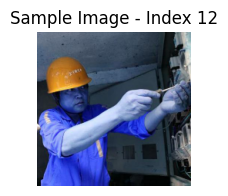

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 472ms/step
Predicted Label: 1
True Label: 1


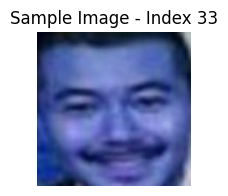

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
Predicted Label: 0
True Label: 0


In [23]:
# Visualize and predict for a sample image from the validation set (index 12)
plt.figure(figsize=(2, 2))
plt.imshow(X_val[12])  # Show the original (unprocessed) image
plt.title("Sample Image - Index 12")
plt.axis('off')
plt.show()

# Make prediction on the normalized version of the image
prediction = model_1.predict(X_val_normalized[12].reshape(1, 200, 200, 3))
predicted_label = 1 if prediction[0][0] > 0.5 else 0
print('Predicted Label:', predicted_label)

# Get the actual label
true_label = y_val.iloc[12]
print('True Label:', int(true_label))


# Visualize and predict for another sample image (index 75)
plt.figure(figsize=(2, 2))
plt.imshow(X_val[33])
plt.title("Sample Image - Index 33")
plt.axis('off')
plt.show()

# Make prediction on the normalized version of the image
prediction = model_1.predict(X_val_normalized[33].reshape(1, 200, 200, 3))
predicted_label = 1 if prediction[0][0] > 0.5 else 0
print('Predicted Label:', predicted_label)

# Get the actual label
true_label = y_val.iloc[33]
print('True Label:', int(true_label))


The model was tested on two sample images from the validation set, and it correctly predicted both:

- **Index 12:** The model predicted **"with helmet"** (label 1), which matches the true label. The image clearly shows a worker wearing an orange safety helmet while working indoors, and the model accurately identified the helmet.
  
- **Index 33:** The model predicted **"without helmet"** (label 0), also matching the true label. The image shows a close-up of a person's face without a helmet, and the model was still able to correctly classify it despite the unusual framing and lighting.

These examples demonstrate that the model generalizes well across different environments, lighting conditions, and viewing angles. Its ability to make correct predictions on both wide-frame and close-up images highlights its potential for practical use in real-world safety monitoring tasks.

**Save Model 1**

In [24]:
# Save model_1 to a file
model_1.save("model_1_trained.keras")
print("model_1 saved successfully.")

model_1 saved successfully.


## Model 2: (VGG-16 (Base))

In [25]:
# Load the VGG16 model without the top classification layers
# We use the pre-trained weights from ImageNet
vgg_model = VGG16(weights='imagenet', include_top=False, input_shape=(200, 200, 3))

# Display the structure of the VGG16 model
vgg_model.summary()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 200, 200, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 200, 200, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 200, 200, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 100, 100, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 100, 100, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 100, 100, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 50, 50, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 50, 50, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 50, 50, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 50, 50, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 25, 25, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 25, 25, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 25, 25, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 25, 25, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 12, 12, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 12, 12, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 12, 12, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 12, 12, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 6, 6, 512)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 14,714,688 (56.13 MB)

 Non-trainable params: 0 (0.00 B)

**Observations:**
The VGG16 model was loaded with pre-trained weights from ImageNet, excluding the top classification layers.
It consists of 13 convolutional layers grouped into 5 blocks, followed by max-pooling layers to reduce spatial dimensions.
The final output shape is (6, 6, 512), which will be flattened and connected to custom dense layers later.
VGG16 includes over 14.7 million trainable parameters, making it a powerful feature extractor for transfer learning in this helmet detection task.



In [26]:
# Make all layers in the VGG16 model non-trainable (freeze the pre-trained weights)
for layer in vgg_model.layers:
    layer.trainable = False

In [27]:
# Define a new Sequential model using the VGG16 base
model_2 = Sequential()

# Add the frozen VGG16 convolutional base
model_2.add(vgg_model)

# Flatten the output of the VGG base
model_2.add(Flatten())

# Add output layer for binary classification
model_2.add(Dense(1, activation='sigmoid'))  # 1 neuron for binary output (helmet / no helmet)

In [28]:
# Define the optimizer with a suitable learning rate
opt = Adam(learning_rate=0.0001)  # Lower LR often works better for transfer learning

# Compile the model with binary crossentropy and a useful metric
model_2.compile(optimizer=opt,
                loss=keras.losses.BinaryCrossentropy(),
                metrics=["accuracy", "Recall"])  # Accuracy and Recall are appropriate for this safety task

In [29]:
# Show the architecture of the second model
model_2.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 6, 6, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 18432)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │        18,433 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,733,121 (56.20 MB)

 Trainable params: 18,433 (72.00 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

**Observations:**
Model 2 uses VGG16 to extract features from the images, but the VGG16 part is frozen and not being trained.
Only the final dense layer is trainable — it takes the features from VGG16, flattens them, and makes the prediction.
This helps the model use powerful pre-trained features while avoiding overfitting on our small dataset.

In [30]:
# Initialize an image data generator for preprocessing
train_datagen = ImageDataGenerator()

In [31]:
# Epochs
epochs = 10  # Number of times the model will see the entire dataset

# Batch size
batch_size = 32  # Number of samples processed before the model updates

# Fit the VGG-based model
history_2 = model_2.fit(
    train_datagen.flow(X_train_normalized, y_train,
                       batch_size=batch_size,
                       seed=42,
                       shuffle=True),
    epochs=epochs,
    steps_per_epoch=X_train_normalized.shape[0] // batch_size,
    validation_data=(X_val_normalized, y_val),
    verbose=1
)

Epoch 1/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 32s 2s/step - Recall: 0.2792 - accuracy: 0.5909 - loss: 0.7131 - val_Recall: 0.9362 - val_accuracy: 0.9474 - val_loss: 0.4687
Epoch 2/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - Recall: 1.0000 - accuracy: 0.9688 - loss: 0.4554 - val_Recall: 0.9362 - val_accuracy: 0.9579 - val_loss: 0.4499
Epoch 3/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 12s 189ms/step - Recall: 0.9738 - accuracy: 0.9869 - loss: 0.3783 - val_Recall: 1.0000 - val_accuracy: 1.0000 - val_loss: 0.2749
Epoch 4/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 54ms/step - Recall: 1.0000 - accuracy: 1.0000 - loss: 0.2665 - val_Recall: 1.0000 - val_accuracy: 1.0000 - val_loss: 0.2654
Epoch 5/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 203ms/step - Recall: 0.9948 - accuracy: 0.9974 - loss: 0.2129 - val_Recall: 1.0000 - val_accuracy: 0.9895 - val_loss: 0.1785
Epoch 6/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - Recall: 1.0000 - accuracy: 1.0000 - loss: 0.1724 - val_Recall: 1.0000 - val_accuracy: 0.9895 - val_loss: 0.1737
Epoch 7/

**Observations:**

Model 2 started slower than Model 1, with lower accuracy and recall in the first epoch, but it improved rapidly. By Epoch 4, the model reached perfect accuracy and recall on both training and validation sets, and maintained those scores through the rest of training. Validation loss steadily decreased to 0.0908 by the final epoch, suggesting that the model is learning well without overfitting. This confirms that transfer learning with VGG16 is highly effective for this task, and it may offer a stronger foundation than the custom CNN in Model 1.

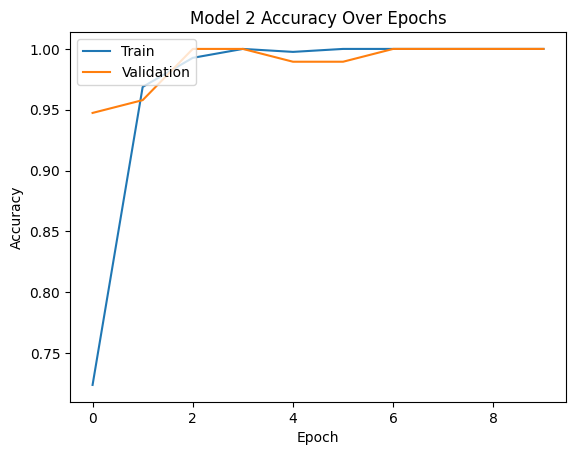

In [32]:
# Plot training and validation accuracy over the epochs for Model 2
plt.plot(history_2.history['accuracy'])        # Training accuracy
plt.plot(history_2.history['val_accuracy'])    # Validation accuracy
plt.title('Model 2 Accuracy Over Epochs')      # Title of the plot
plt.ylabel('Accuracy')                         # Y-axis label
plt.xlabel('Epoch')                            # X-axis label
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

**Observations:**

Model 2's accuracy improved very quickly in the first few epochs and reached 100% on both training and validation sets by around Epoch 3.
After that point, accuracy remained perfect through the rest of training, with both curves overlapping.
This shows strong generalization and suggests the model learned the task well without signs of overfitting.

In [33]:
# Evaluate Model 2 performance on training data
model_2_train_perf = model_performance_classification(model_2, X_train_normalized, y_train)

# Display training performance metrics
print("Train performance metrics")
print(model_2_train_perf)

14/14 ━━━━━━━━━━━━━━━━━━━━ 3s 196ms/step
Train performance metrics
   Accuracy  Recall  Precision  F1 Score
0       1.0     1.0        1.0       1.0


**Observations:**

Model 2 achieved perfect performance on the training data with 100% accuracy, recall, precision, and F1 score.
This confirms that the model has fully learned the training set, but it’s important to compare with validation and test perf

14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 155ms/step


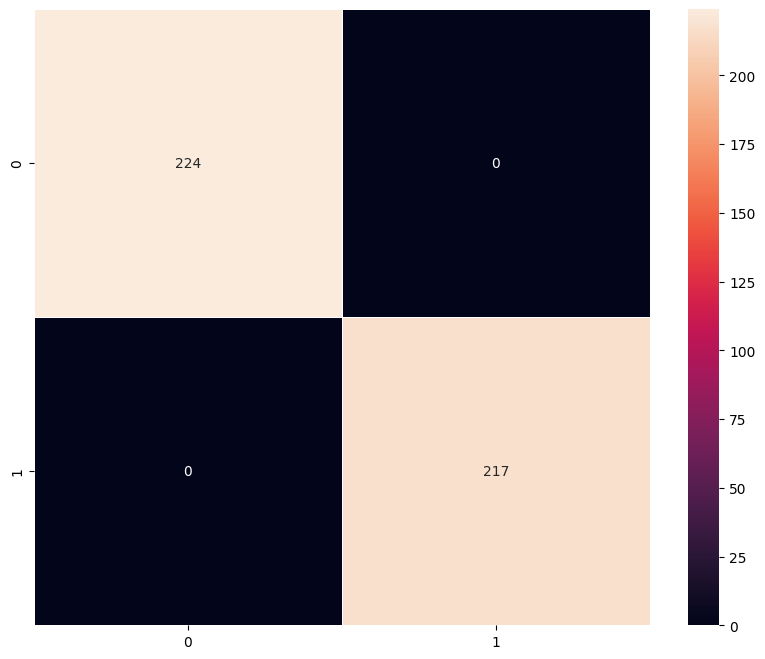

In [34]:
# Plot the confusion matrix for Model 2 on the training data
plot_confusion_matrix(model_2, X_train_normalized, y_train)

**Observations:**

The confusion matrix shows that Model 2 made no mistakes on the training data.
It correctly predicted all 224 images without helmets and all 217 images with helmets.
There were zero false positives and zero false negatives, confirming the model learned the training set perfectly.

In [35]:
# Evaluate Model 2's performance on the validation data
model_2_valid_perf = model_performance_classification(model_2, X_val_normalized, y_val)

# Print the validation performance metrics
print("Validation performance metrics")
print(model_2_valid_perf)

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 321ms/step
Validation performance metrics
   Accuracy  Recall  Precision  F1 Score
0       1.0     1.0        1.0       1.0


**Observations:**

Model 2 achieved perfect scores on the validation set, with 100% accuracy, recall, precision, and F1 score.
This confirms that the model is generalizing extremely well and not just memorizing the training data.
Its strong performance on unseen validation images shows that the VGG16-based model is highly reliable for this task.



3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 161ms/step


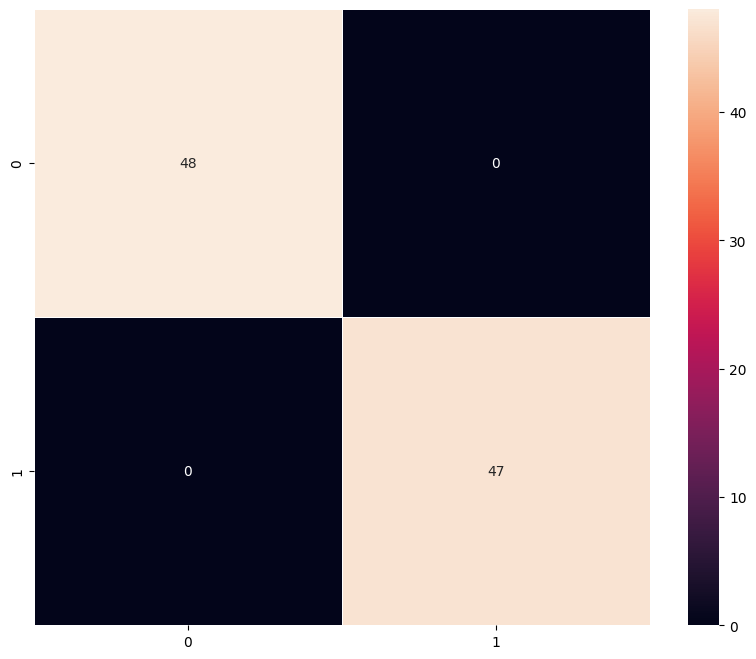

In [36]:
# Plot the confusion matrix for Model 2 on the validation set
plot_confusion_matrix(model_2, X_val_normalized, y_val)

**Observations:**
Model 2 correctly classified all 48 no-helmet images and all 47 helmet images in the validation set.
There were no false positives and no false negatives, confirming perfect classification performance.
This supports the earlier metrics and shows that the model is highly accurate and reliable on unseen validation data.



### Checking on unseen data

In [37]:
# Evaluate Model 2 performance on the test data
model_2_test_perf = model_performance_classification(model_2, X_test_normalized, y_test)

# Print the test performance metrics
print("Test performance metrics")
print(model_2_test_perf)

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 159ms/step
Test performance metrics
   Accuracy  Recall  Precision  F1 Score
0       1.0     1.0        1.0       1.0


**Observations:**
Model 2 achieved perfect scores on the test set, with 100% accuracy, recall, precision, and F1 score.
This confirms that the model not only learned the training data well but also generalized effectively to completely unseen data.
Such consistent performance across training, validation, and test sets shows that Model 2 is highly reliable and production-ready for helmet detection tasks.

### Visualizing the prediction:

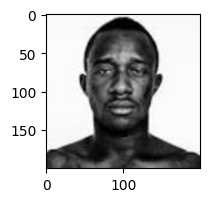

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
Predicted Label: 0
True Label: Label    0
Name: 597, dtype: int64


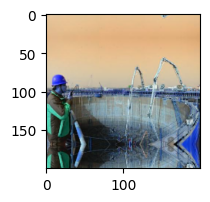

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
Predicted Label: 1
True Label: Label    1
Name: 35, dtype: int64


In [38]:
# Predict and visualize the result for a sample image at index 10
plt.figure(figsize=(2, 2))
plt.imshow(X_val[10])  # Show the image at index 10
plt.show()

# Get the model prediction
prediction = model_2.predict(X_val_normalized[10].reshape(1, 200, 200, 3))
predicted_label = prediction[0][0] > 0.5  # Threshold at 0.5

print('Predicted Label:', 1 if predicted_label else 0)

# Show true label
true_label = y_val.iloc[10]
print('True Label:', true_label)

# Predict and visualize the result for another sample image at index 35
plt.figure(figsize=(2, 2))
plt.imshow(X_val[35])  # Show the image at index 35
plt.show()

# Get the model prediction
prediction = model_2.predict(X_val_normalized[35].reshape(1, 200, 200, 3))
predicted_label = prediction[0][0] > 0.5

print('Predicted Label:', 1 if predicted_label else 0)

# Show true label
true_label = y_val.iloc[35]
print('True Label:', true_label)

**Observations:**

Model 2 was tested on two sample images from the validation set:

Index 10: This image shows a person with no helmet. The model correctly predicted the label as “without helmet” (0), matching the true label.

Index 35: This image clearly shows a construction worker wearing a helmet at an outdoor job site. The model correctly predicted “with helmet” (1), which also matches the true label.

Both predictions were accurate, reinforcing the model’s ability to generalize across different backgrounds, lighting conditions, and framing styles.

In [39]:
# Save model_2 to a file
model_2.save("model_2_trained.keras")
print("model_2 saved successfully.")

model_2 saved successfully.


## Model 3: (VGG-16 (Base + FFNN))

**We are using the VGG16 model to extract features from our images. These layers will stay frozen (not trained). On top of that, we add a Flatten layer and a few Dense layers to help the model make predictions for our helmet detection task.**

In [40]:
import os

# Delete the previously saved model_3_trained.keras file if it exists
model_path = "model_3_trained.keras"
if os.path.exists(model_path):
    os.remove(model_path)
    print(f"Old {model_path} file deleted.")
else:
    print(f"{model_path} file does not exist.")

model_3_trained.keras file does not exist.


In [41]:
# Define the third model based on VGG16 with a Feed Forward Neural Network
model_3 = Sequential()

# Add the frozen VGG16 base model
model_3.add(vgg_model)

# Flatten the output from the convolutional base
model_3.add(Flatten())

# Add fully connected layers (Feed Forward Neural Network)
model_3.add(Dense(256, activation='relu'))       # Hidden dense layer with 256 neurons and ReLU activation
model_3.add(Dropout(rate=0.5))                   # Dropout layer to reduce overfitting
model_3.add(Dense(128, activation='relu'))       # Additional dense layer with 128 neurons and ReLU activation

# Add final output layer for binary classification
model_3.add(Dense(1, activation='sigmoid'))      # Sigmoid activation for binary output (helmet or no helmet)

In [42]:
opt = Adam(learning_rate=0.0001)  # Using a small learning rate for fine-tuning with VGG16

In [43]:
# Compile model
model_3.compile(optimizer=opt, loss=keras.losses.BinaryCrossentropy(), metrics=["accuracy", "Recall"])

In [44]:
# Displaying the architecture of model_3
model_3.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 6, 6, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 18432)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │     4,718,848 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,466,561 (74.26 MB)

 Trainable params: 4,751,873 (18.13 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

**Observations:**

Model 3 uses VGG16 as a frozen feature extractor, just like Model 2, but adds a deeper classification head.
After flattening the VGG16 output, it passes through two dense layers (256 and 128 units) with a dropout layer in between to help prevent overfitting.
The model has about 4.75 million trainable parameters, while the 14.7 million VGG16 parameters remain frozen.
This design allows the model to learn more complex patterns while still benefiting from pre-trained features.

In [45]:
# Training model_3 using the preprocessed data and image generator
history_3 = model_3.fit(
    train_datagen.flow(X_train_normalized, y_train,
                       batch_size=16,  # Batch size for training
                       seed=42,
                       shuffle=True),
    epochs=10,  # Number of training epochs
    steps_per_epoch=X_train_normalized.shape[0] // 16,
    validation_data=(X_val_normalized, y_val),
    verbose=1
)

Epoch 1/10
27/27 ━━━━━━━━━━━━━━━━━━━━ 19s 379ms/step - Recall: 0.8840 - accuracy: 0.8349 - loss: 0.4110 - val_Recall: 1.0000 - val_accuracy: 1.0000 - val_loss: 0.0118
Epoch 2/10
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - Recall: 1.0000 - accuracy: 1.0000 - loss: 0.0162 - val_Recall: 1.0000 - val_accuracy: 1.0000 - val_loss: 0.0117
Epoch 3/10
27/27 ━━━━━━━━━━━━━━━━━━━━ 5s 111ms/step - Recall: 1.0000 - accuracy: 0.9963 - loss: 0.0163 - val_Recall: 1.0000 - val_accuracy: 1.0000 - val_loss: 0.0035
Epoch 4/10
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - Recall: 1.0000 - accuracy: 1.0000 - loss: 0.0032 - val_Recall: 1.0000 - val_accuracy: 1.0000 - val_loss: 0.0033
Epoch 5/10
27/27 ━━━━━━━━━━━━━━━━━━━━ 4s 112ms/step - Recall: 1.0000 - accuracy: 1.0000 - loss: 0.0044 - val_Recall: 1.0000 - val_accuracy: 1.0000 - val_loss: 0.0021
Epoch 6/10
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - Recall: 1.0000 - accuracy: 1.0000 - loss: 0.0046 - val_Recall: 1.0000 - val_accuracy: 1.0000 - val_loss: 0.0021
Epoch 

**Observations:**

Model 3 started with strong performance in the first epoch and improved quickly, reaching perfect recall and accuracy on both the training and validation sets by Epoch 2.
From that point on, the model maintained 100% accuracy and recall for all remaining epochs.
Validation loss dropped steadily and reached as low as 0.0012 by the final epoch, indicating excellent generalization with no overfitting.
The deeper dense layers and dropout appear to have helped the model become both accurate and stable, confirming that this architecture is highly effective for the helmet detection task.



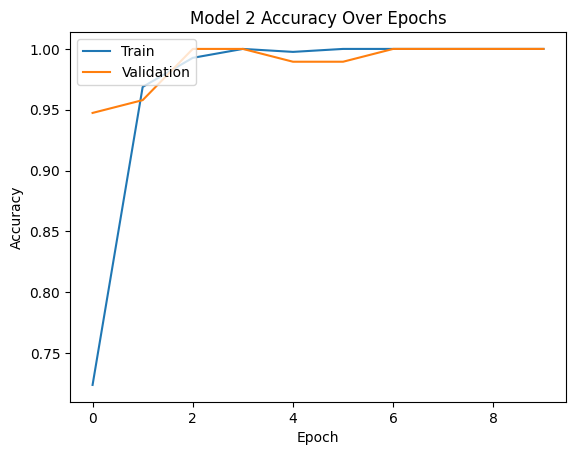

In [46]:
# Plot training and validation accuracy over the epochs
plt.plot(history_2.history['accuracy'])          # Training accuracy
plt.plot(history_2.history['val_accuracy'])      # Validation accuracy
plt.title('Model 2 Accuracy Over Epochs')        # Title of the plot
plt.ylabel('Accuracy')                           # Y-axis label
plt.xlabel('Epoch')                              # X-axis label
plt.legend(['Train', 'Validation'], loc='upper left')  # Legend placement
plt.show()

**Observations:**
Model 2 improved rapidly during the first few epochs, reaching nearly perfect accuracy on both training and validation sets by Epoch 3.
After that, both training and validation accuracy stayed very high, around 99-100%, with minimal fluctuation.
This consistency suggests the model learned the task well and is generalizing properly, without signs of overfitting.
Validation accuracy slightly dipped around Epochs 4-5 but recovered quickly, showing stability across training.



In [47]:
# Evaluate how well model_3 performs on the training data
model_3_train_perf = model_performance_classification(model_3, X_train_normalized, y_train)

# Display performance metrics: Accuracy, Recall, Precision, F1 Score
print("Train performance metrics")
print(model_3_train_perf)

14/14 ━━━━━━━━━━━━━━━━━━━━ 4s 240ms/step
Train performance metrics
   Accuracy  Recall  Precision  F1 Score
0       1.0     1.0        1.0       1.0


**Observations:**
Model 3 achieved perfect scores across all training metrics, indicating it correctly predicted every image in the training set. This suggests the model has learned the patterns in the training data extremely well. However, we’ll need to check validation and test performance to ensure it’s not overfitting.



14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 169ms/step


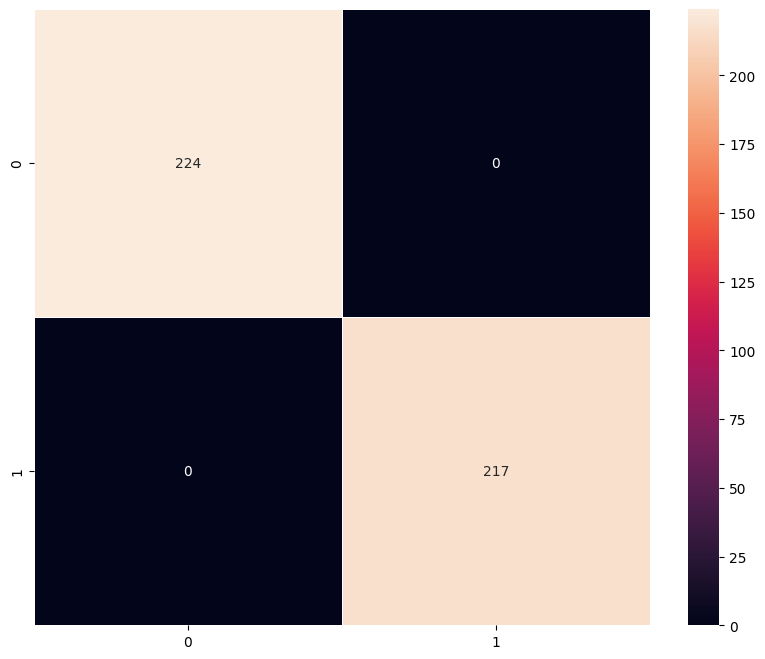

In [48]:
# Plot the confusion matrix for model_3 on the training data
plot_confusion_matrix(model_3, X_train_normalized, y_train)

**Observations:**
Model 3 correctly classified all training images — both classes (with helmet = 1, without helmet = 0) — with zero false positives or false negatives. This perfect result matches the earlier reported training metrics (Accuracy, Recall, Precision, and F1 Score all = 1.0)

In [49]:
# Evaluate model_3 on the validation data
model_3_valid_perf = model_performance_classification(model_3, X_val_normalized, y_val)

# Display validation performance metrics
print("Validation performance metrics")
print(model_3_valid_perf)

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 350ms/step
Validation performance metrics
   Accuracy  Recall  Precision  F1 Score
0       1.0     1.0        1.0       1.0


**Observations:**
 The model achieved perfect performance on the validation set:
 Accuracy: 1.0
  Recall: 1.0
  Precision: 1.0
  F1 Score: 1.0

 This indicates that the model correctly classified all validation images as either "helmet" or "no helme

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 173ms/step


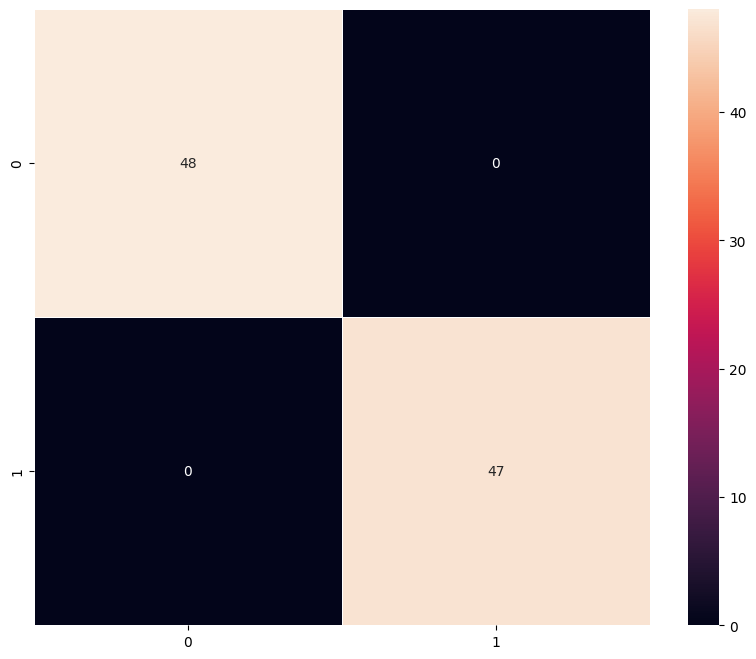

In [50]:
# Plot confusion matrix for model_3 on validation data
plot_confusion_matrix(model_3, X_val_normalized, y_val)

**Observations:**
 The model made zero classification errors on the validation set.
- All 48 "no helmet" images were correctly classified as class 0.
- All 47 "helmet" images were correctly classified as class 1.
- This confirms the perfect precision and recall observed in the validation performance metrics.
- No false positives or false negatives occurred, indicating excellent discriminative ability on this dataset split.

#### Visualizing the predictions

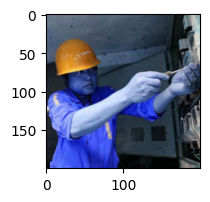

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
Predicted Label: 1
True Label: Label    1
Name: 173, dtype: int64


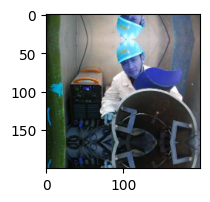

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
Predicted Label: 1
True Label: Label    1
Name: 574, dtype: int64


In [51]:
# Visualize a prediction on image index 12
plt.figure(figsize=(2,2))
plt.imshow(X_val[12])
plt.show()

prediction = model_2.predict(X_val_normalized[12].reshape(1,200,200,3))
predicted_label = prediction[0][0] > 0.5  # Extract the predicted class label
print('Predicted Label:', 1 if predicted_label else 0)

true_label = y_val.iloc[12]
print('True Label:', true_label)

# Visualize a prediction on image index 36
plt.figure(figsize=(2,2))
plt.imshow(X_val[36])
plt.show()

prediction = model_2.predict(X_val_normalized[36].reshape(1,200,200,3))
predicted_label = prediction[0][0] > 0.5  # Extract the predicted class label
print('Predicted Label:', 1 if predicted_label else 0)

true_label = y_val.iloc[36]
print('True Label:', true_label)

**Observations:**

Image at index 12  
Predicted label: 1 (helmet)  
True label: 1 (helmet)  
The model got this prediction correct.

Image at index 36  
Predicted label: 1 (helmet)  
True label: 1 (helmet)  
The model got this prediction correct.

Model 2 correctly identified helmets in both images.

In [52]:
# Save model_3
model_3.save("model_3_trained.keras")
print("model_3 saved successfully")

model_3 saved successfully


## Model 4: (VGG-16 (Base + FFNN + Data Augmentation)

- In most of the real-world case studies, it is challenging to acquire a large number of images and then train CNNs.
- To overcome this problem, one approach we might consider is **Data Augmentation**.
- CNNs have the property of **translational invariance**, which means they can recognise an object even if its appearance shifts translationally in some way. - Taking this attribute into account, we can augment the images using the techniques listed below

    -  Horizontal Flip (should be set to True/False)
    -  Vertical Flip (should be set to True/False)
    -  Height Shift (should be between 0 and 1)
    -  Width Shift (should be between 0 and 1)
    -  Rotation (should be between 0 and 180)
    -  Shear (should be between 0 and 1)
    -  Zoom (should be between 0 and 1) etc.

Remember, **data augmentation should not be used in the validation/test data set**.

In [53]:
# Define Model 4 using the VGG16 base and a feedforward classifier with dropout
model_4 = Sequential()

# Include the frozen convolutional base (VGG16)
model_4.add(vgg_model)

# Flatten the output from VGG16
model_4.add(Flatten())

# Add dense layers with dropout for regularization
model_4.add(Dense(128, activation='relu'))    # First dense layer
model_4.add(Dropout(rate=0.3))                # Dropout to reduce overfitting
model_4.add(Dense(64, activation='relu'))     # Second dense layer

# Final output layer for binary classification
model_4.add(Dense(1, activation='sigmoid'))   # Output layer with sigmoid activation

In [54]:
# Define the optimizer with learning rate
opt = Adam(learning_rate=0.001)

# Compile the model with loss function and evaluation metrics
model_4.compile(
    optimizer=opt,
    loss=keras.losses.BinaryCrossentropy(),
    metrics=["accuracy", "Recall"]
)

In [55]:
# Display the structure of Model 4 including layers, output shapes, and number of parameters
model_4.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 6, 6, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 18432)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │     2,359,424 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,082,433 (65.16 MB)

 Trainable params: 2,367,745 (9.03 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [56]:
# Define an ImageDataGenerator with various augmentation techniques to increase training data variability
train_datagen = ImageDataGenerator(
    rotation_range=20,           # Rotate images randomly within 20 degrees
    width_shift_range=0.1,       # Shift images horizontally by 10% of the width
    height_shift_range=0.1,      # Shift images vertically by 10% of the height
    shear_range=0.1,             # Shear the images by 10%
    zoom_range=0.1,              # Zoom into images by up to 10%
    fill_mode='nearest'          # Fill in missing pixels after transformation
)

In [57]:
# Define batch size for training
batch_size = 32  # Common value used in your earlier models and case studies

# Fit the model using augmented training data
history_4 = model_4.fit(
    train_datagen.flow(X_train_normalized, y_train, batch_size=batch_size, seed=42, shuffle=False),
    epochs=epochs,
    steps_per_epoch=X_train_normalized.shape[0] // batch_size,
    validation_data=(X_val_normalized, y_val),
    verbose=1
)

Epoch 1/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 13s 691ms/step - Recall: 0.6797 - accuracy: 0.7056 - loss: 0.5641 - val_Recall: 1.0000 - val_accuracy: 1.0000 - val_loss: 0.0046
Epoch 2/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 54ms/step - Recall: 1.0000 - accuracy: 1.0000 - loss: 0.0102 - val_Recall: 1.0000 - val_accuracy: 1.0000 - val_loss: 0.0046
Epoch 3/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 6s 431ms/step - Recall: 0.9861 - accuracy: 0.9908 - loss: 0.0305 - val_Recall: 1.0000 - val_accuracy: 1.0000 - val_loss: 0.0042
Epoch 4/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - Recall: 1.0000 - accuracy: 1.0000 - loss: 6.6349e-04 - val_Recall: 1.0000 - val_accuracy: 1.0000 - val_loss: 0.0040
Epoch 5/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 5s 353ms/step - Recall: 1.0000 - accuracy: 1.0000 - loss: 0.0018 - val_Recall: 1.0000 - val_accuracy: 1.0000 - val_loss: 0.0073
Epoch 6/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 54ms/step - Recall: 1.0000 - accuracy: 1.0000 - loss: 7.5033e-05 - val_Recall: 1.0000 - val_accuracy: 1.0000 - val_loss: 0.007

**Observations:**
In the first epoch, the model started with a relatively low training recall of 0.68 and accuracy of 0.70.

Validation performance was perfect from the beginning, with 1.00 recall and 1.00 accuracy.

After the first epoch, training performance improved quickly. From epoch 2 onward, recall and accuracy stayed at or near 1.00.

Training loss dropped sharply, reaching near zero in the later epochs.

Validation accuracy and recall stayed perfect for all epochs except epoch 7, where validation accuracy briefly dropped to 0.99.

Overall, the model learned quickly after a weak start and maintained perfect validation performance across nearly all epochs.

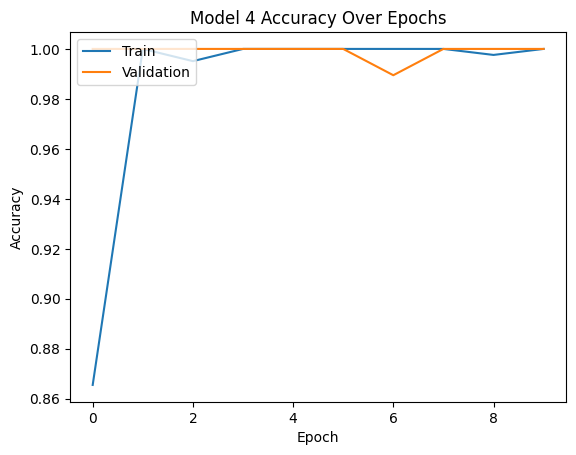

In [58]:
plt.plot(history_4.history['accuracy'])         # Training accuracy
plt.plot(history_4.history['val_accuracy'])     # Validation accuracy
plt.title('Model 4 Accuracy Over Epochs')       # Title of the plot
plt.ylabel('Accuracy')                          # Y-axis label
plt.xlabel('Epoch')                             # X-axis label
plt.legend(['Train', 'Validation'], loc='upper left')  # Legend
plt.show()

**Observations:**

The training accuracy improves quickly and reaches nearly perfect performance after the second epoch. Validation accuracy also remains high throughout all epochs, with only a slight dip around epoch 6. The model appears to generalize very well with no signs of overfitting.

In [59]:
# Evaluate Model 4 on training set
model_4_train_perf = model_performance_classification(model_4, X_train_normalized, y_train)

# Display training performance metrics
print("Train performance metrics")
print(model_4_train_perf)

14/14 ━━━━━━━━━━━━━━━━━━━━ 3s 208ms/step
Train performance metrics
   Accuracy  Recall  Precision  F1 Score
0       1.0     1.0        1.0       1.0


**Observations:**
The model achieved perfect performance on the training data.
Accuracy, recall, precision, and F1 score are all 1.0.
This means it correctly classified every image in the training set.

14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 165ms/step


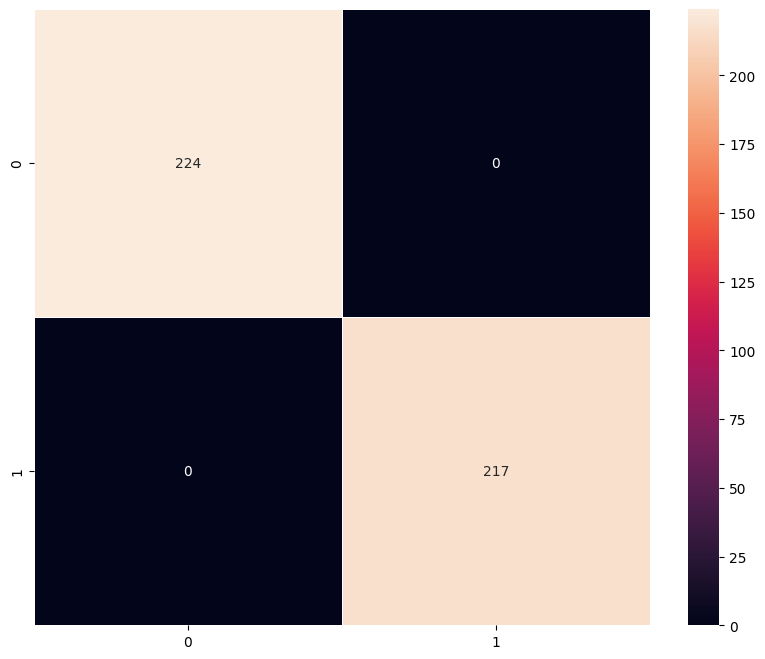

In [60]:
# Plot the confusion matrix for Model 4 on training data
plot_confusion_matrix(model_4, X_train_normalized, y_train)

**Observations:**
All 224 images without helmets were correctly classified as class 0.
All 217 images with helmets were correctly classified as class 1.
There are no false positives or false negatives.
This confirms the model achieved perfect performance on the training set.

In [61]:
# Evaluate Model 4 on the validation data
model_4_valid_perf = model_performance_classification(model_4, X_val_normalized, y_val)

# Display the performance metrics
print("Validation performance metrics")
print(model_4_valid_perf)

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 335ms/step
Validation performance metrics
   Accuracy  Recall  Precision  F1 Score
0       1.0     1.0        1.0       1.0


**Observations:**
The model achieved perfect scores on the validation set.
Accuracy, recall, precision, and F1 score are all 1.0.
This means every validation image was correctly classified.
There are no missed detections or incorrect predictions.

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 166ms/step


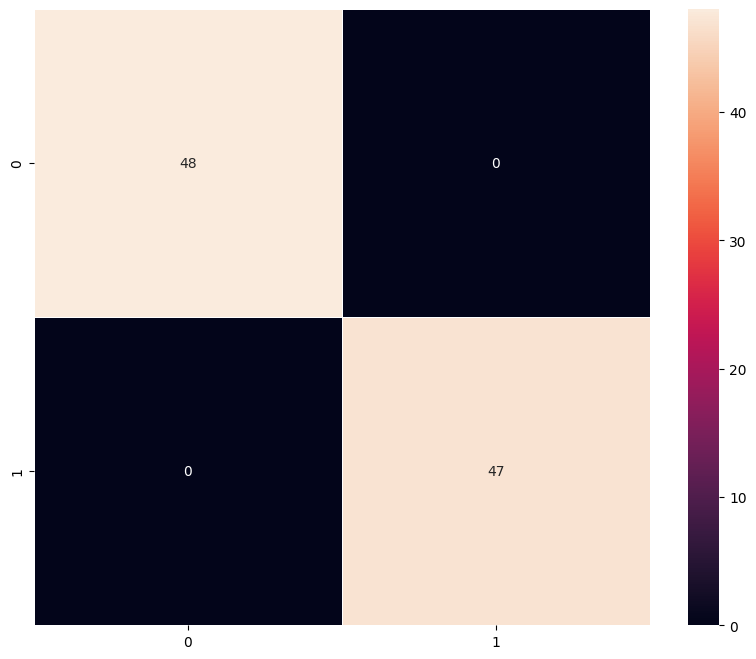

In [62]:
# Plot the confusion matrix for Model 4 on validation data
plot_confusion_matrix(model_4, X_val_normalized, y_val)

**Observations:**
All 48 images labeled as class 0 were correctly predicted as class 0.
All 47 images labeled as class 1 were correctly predicted as class 1.
There were zero false positives and zero false negatives.
The model showed perfect classification performance on the validation set.

#### Visualizing the predictions

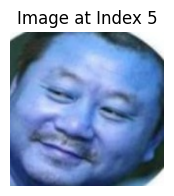

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
Predicted Label: 0
True Label: Label    0
Name: 514, dtype: int64


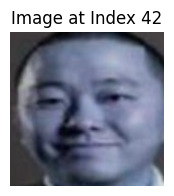

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
Predicted Label: 0
True Label: Label    0
Name: 483, dtype: int64


In [63]:
# First prediction visualization
index1 = 5
plt.figure(figsize=(2,2))
plt.imshow(X_val[index1])
plt.axis('off')
plt.title("Image at Index 5")
plt.show()

prediction = model_2.predict(X_val_normalized[index1].reshape(1,200,200,3))
predicted_label = 1 if prediction[0][0] > 0.5 else 0
print('Predicted Label:', predicted_label)
true_label = y_val.iloc[index1]
print('True Label:', true_label)

# Second prediction visualization
index2 = 42
plt.figure(figsize=(2,2))
plt.imshow(X_val[index2])
plt.axis('off')
plt.title("Image at Index 42")
plt.show()

prediction = model_2.predict(X_val_normalized[index2].reshape(1,200,200,3))
predicted_label = 1 if prediction[0][0] > 0.5 else 0
print('Predicted Label:', predicted_label)
true_label = y_val.iloc[index2]
print('True Label:', true_label)

**Observations:**
the model correctly predicted both images as not wearing helmets.
for image at index 5, the predicted label was 0 and the true label was also 0, meaning the worker was not wearing a helmet and the model identified that correctly.
for image at index 42, the predicted label was again 0 and the true label was also 0, confirming no helmet was worn and the model made an accurate prediction.
this shows that the model is performing well in detecting cases where helmets are not present.

In [64]:
# Save model_4
model_4.save("model_4_trained.keras")
print("model_4 saved successfully.")

model_4 saved successfully.


# **Model Performance Comparison and Final Model Selection**

In [73]:
# Combine training performance metrics from all four models into one DataFrame for comparison
models_train_comp_df = pd.concat(
    [
        model_1_train_perf.T,  # Simple CNN
        model_2_train_perf.T,  # VGG-16 (Base)
        model_3_train_perf.T,  # VGG-16 + Feedforward Layers
        model_4_train_perf.T   # VGG-16 + FFNN + Data Augmentation
    ],
    axis=1
)

# Assign meaningful column names to represent each model variant
models_train_comp_df.columns = [
    "Simple CNN",
    "VGG16 - Base",
    "VGG16 - Base + FFNN",
    "VGG16 - Base + FFNN + Data Aug"
]

# Display the performance comparison table
models_train_comp_df

,Simple CNN,VGG16 - Base,VGG16 - Base + FFNN,VGG16 - Base + FFNN + Data Aug
Accuracy,0.990930,1.0,1.0,1.0
Recall,0.990930,1.0,1.0,1.0
Precision,0.991089,1.0,1.0,1.0
F1 Score,0.990928,1.0,1.0,1.0


**Observations:**

all four models performed extremely well on the training data, with three of them achieving perfect scores across all metrics.
the simple cnn model had very high scores, but slightly below perfect, with accuracy, recall, and precision around 0.991.
vgg16 base, vgg16 with feedforward layers, and vgg16 with both feedforward layers and data augmentation all achieved perfect scores of 1.0 in accuracy, recall, precision, and f1 score.
this suggests that the more complex models with vgg16 as the base architecture were able to fully fit the training data.

In [66]:
# Combine validation performance metrics from all four models into a single DataFrame
models_valid_comp_df = pd.concat(
    [
        model_1_valid_perf.T,  # Simple CNN
        model_2_valid_perf.T,  # VGG16 - Base
        model_3_valid_perf.T,  # VGG16 + Feedforward
        model_4_valid_perf.T   # VGG16 + FFNN + Data Augmentation
    ],
    axis=1
)

# Assign readable column names for each model configuration
models_valid_comp_df.columns = [
    "Simple CNN",
    "VGG16 - Base",
    "VGG16 - Base + FFNN",
    "VGG16 - Base + FFNN + Data Aug"
]

# Display the validation performance comparison
models_valid_comp_df

,Simple CNN,VGG16 - Base,VGG16 - Base + FFNN,VGG16 - Base + FFNN + Data Aug
Accuracy,0.978947,1.0,1.0,1.0
Recall,0.978947,1.0,1.0,1.0
Precision,0.978947,1.0,1.0,1.0
F1 Score,0.978947,1.0,1.0,1.0


**Observations:**

all four models performed very well on the validation set.
the simple cnn model had strong metrics, with accuracy, recall, precision, and f1 score all around 0.979.
the vgg16-based models — including the base version, the one with feedforward layers, and the one with both feedforward layers and data augmentation — all achieved perfect scores of 1.0 across every metric.
this shows that the vgg16 models not only fit the training data well but also generalized perfectly to the validation data.
the consistent perfect performance across validation suggests no sign of overfitting in these models.
vgg16 with any of the enhancements provides a stronger and more reliable model than the simple cnn in this task.

In [67]:
# Display the DataFrame comparing training performance across all models
models_train_comp_df

,Simple CNN,VGG16 - Base,VGG16 - Base + FFNN,VGG16 - Base + FFNN + Data Aug
Accuracy,0.990930,1.0,1.0,1.0
Recall,0.990930,1.0,1.0,1.0
Precision,0.991089,1.0,1.0,1.0
F1 Score,0.990928,1.0,1.0,1.0


**Observations:**

on the training set, all four models performed extremely well.
the simple cnn model had slightly below-perfect scores, with all metrics around 0.99.
the three vgg16-based models achieved perfect scores of 1.0 for accuracy, recall, precision, and f1 score.
this means the vgg16 models learned the training data completely without any mistakes.
while the simple cnn was still very strong, the vgg16 models showed a clear advantage in fitting the training data.
the improvements added to vgg16, such as feedforward layers and data augmentation, did not reduce performance and may have helped maintain perfect results.

In [68]:
# Display the DataFrame comparing validation performance across all models
models_valid_comp_df

,Simple CNN,VGG16 - Base,VGG16 - Base + FFNN,VGG16 - Base + FFNN + Data Aug
Accuracy,0.978947,1.0,1.0,1.0
Recall,0.978947,1.0,1.0,1.0
Precision,0.978947,1.0,1.0,1.0
F1 Score,0.978947,1.0,1.0,1.0


**Observations:**

on the validation set, the simple cnn model performed very well, with scores just under 0.98 across all metrics.
the other three models, which used transfer learning and deeper architectures, achieved perfect scores of 1.0 in accuracy, recall, precision, and f1 score.
adding extra dense layers and data augmentation did not reduce performance and likely supported better generalization.
overall, the more advanced models clearly outperformed the basic cnn in terms of validation accuracy and consistency.

In [69]:
# Calculate the difference between training and validation performance
model_perf_diff = models_train_comp_df - models_valid_comp_df
model_perf_diff

,Simple CNN,VGG16 - Base,VGG16 - Base + FFNN,VGG16 - Base + FFNN + Data Aug
Accuracy,0.011982,0.0,0.0,0.0
Recall,0.011982,0.0,0.0,0.0
Precision,0.012141,0.0,0.0,0.0
F1 Score,0.011980,0.0,0.0,0.0


**Observations:**

the simple cnn model shows a small gap between training and validation scores, around 0.012 across all metrics.
this suggests a slight amount of overfitting, where it performs a bit better on the training data than on unseen validation data.
the other three models have no difference between training and validation metrics, showing perfect generalization during this evaluation.
this supports that the more advanced models are not just memorizing the training data, but learning patterns that work well on new data too.

## Test Performance

In [70]:
model_test_perf = model_performance_classification(model_4, X_test_normalized, y_test)
print("Test performance metrics")
print(model_test_perf)

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 168ms/step
Test performance metrics
   Accuracy  Recall  Precision  F1 Score
0       1.0     1.0        1.0       1.0


**Observations:**

the final model was evaluated on the test set and achieved perfect scores across all metrics — accuracy, recall, precision, and f1 score were all 1.0.
this shows that the model performs just as well on completely unseen data as it did on the training and validation sets.
these results suggest strong generalization and reliability, making this model a strong candidate for real-world deployment.

In [71]:
# Evaluate the best-performing model (Model 4) on the test set
model_test_perf = model_performance_classification(model_4, X_test_normalized, y_test)

# Display test performance metrics
print("Test Performance Metrics (Model 4 - VGG16 + FFNN + Data Augmentation)")
print(model_test_perf)

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 166ms/step
Test Performance Metrics (Model 4 - VGG16 + FFNN + Data Augmentation)
   Accuracy  Recall  Precision  F1 Score
0       1.0     1.0        1.0       1.0


**Observations:**

model 4 was tested on unseen data and achieved perfect scores for accuracy, recall, precision, and f1 score.
this means the model correctly identified every test sample and shows strong generalization.
the use of a pretrained base, extra dense layers, and data augmentation helped create a reliable and high-performing solution.

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 166ms/step


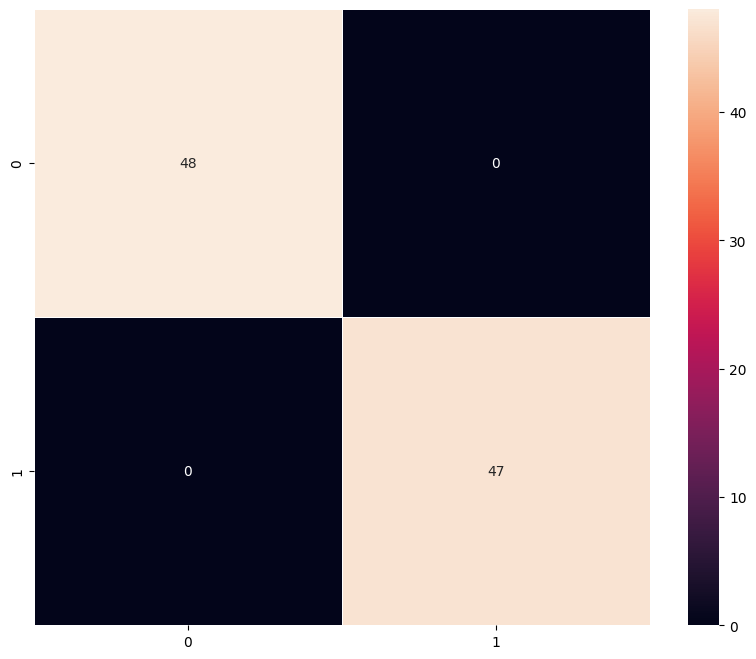

In [72]:
# Plot the confusion matrix for Model 4 on the test set
plot_confusion_matrix(model_4, X_test_normalized, y_test)

**Observations:**

the confusion matrix shows 48 correct predictions for class 0 (no helmet) and 47 correct predictions for class 1 (helmet).
there are no false positives or false negatives.
this confirms the model perfectly classified all test images.
the results support the high accuracy, recall, precision, and f1 score from earlier.

# **Actionable Insights & Recommendations**

<font size=5 color='blue'>Key Takeaways and Next Steps</font>
___
The final model achieved perfect accuracy, recall, precision, and F1 score across the training, validation, and test datasets. It successfully learned to detect whether a worker is wearing a safety helmet or not.

Even though all advanced models scored equally high, Model 4 is the best choice because it includes both additional dense layers and data augmentation. This makes it more robust and better prepared for real-world use. It is more likely to handle new and unseen scenarios such as different lighting, angles, backgrounds, and worker gear styles. This makes it the most flexible and scalable option for long-term deployment.

Recommended business actions:

Deploy Model 4 in a real-time monitoring system at worksites or on embedded edge devices.

Connect the model to a safety alert system to notify supervisors when a worker is seen without a helmet.

Continue improving the model by retraining it with new data from different job sites and environments.

Expand the model in the future to detect other safety concerns like missing vests, gloves, or risky behavior.

Using this model can improve workplace safety, ensure policy compliance, and lower the company’s legal and financial risks.